Complete the exercises below For **Assignment #5**.

In this exercise, we are building a logistic regression classification model. We'll work with the [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).  

Load the `tidymodels` library. 

In [1]:
library(tidymodels)



── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.13     ✔ recipes      1.3.3 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



The data is located in your homework directory in the `diabetes.csv` file. Read in the data by running the following cell. We are "splitting" the data into training and testing sets. We will evaluate our model's performance with the test set.

In [4]:
diabetes = readr::read_csv('diabetes.csv') |> mutate(Outcome = factor(Outcome))

split = initial_split(diabetes, strata = Outcome)

diabetes_train = training(split)
diabetes_test = testing(split)



Rows: 768 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, D...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Glimpse the `diabetes_train` table.

In [5]:
glimpse(diabetes_train)



Rows: 576
Columns: 9
$ Pregnancies              <dbl> 1, 10, 4, 10, 1, 3, 13, 5, 5, 6, 10, 4, 11, 3…
$ Glucose                  <dbl> 89, 115, 110, 139, 103, 126, 145, 117, 109, 9…
$ BloodPressure            <dbl> 66, 0, 92, 80, 30, 88, 82, 92, 75, 92, 78, 60…
$ SkinThickness            <dbl> 23, 0, 0, 0, 38, 41, 19, 0, 26, 0, 31, 33, 0,…
$ Insulin                  <dbl> 94, 0, 0, 0, 83, 235, 110, 0, 0, 0, 0, 192, 0…
$ BMI                      <dbl> 28.1, 35.3, 37.6, 27.1, 43.3, 39.3, 22.2, 34.…
$ DiabetesPedigreeFunction <dbl> 0.167, 0.134, 0.191, 1.441, 0.183, 0.704, 0.2…
$ Age                      <dbl> 21, 29, 30, 57, 33, 27, 57, 38, 60, 28, 45, 3…
$ Outcome                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


❓ Which variable is suitable as the "outcome" in a logistic regression model?

**Answer:**

Outcome

❓ Navigate to [Kaggle page](https://www.kaggle.com/datasets/mathchi/diabetes-data-set) for this dataset. Find descriptions for the `Glucose` and `BMI` columns. Add these descriptions to the [Markdown table](https://www.markdownguide.org/extended-syntax/#tables) below.

| Column name | Description |
| :---------- | :---------- |
| Glucose     | Plasma glucose concentration measured 2 hours after an oral glucose tolerance test        |
| BMI         | Body Mass Index, calculated as weight in kilograms divided by height in meters squared (kg/m2)          |

Make a bar chart showing the frequency of each "outcome" in the `Outcome` column from your `diabetes_train` data.

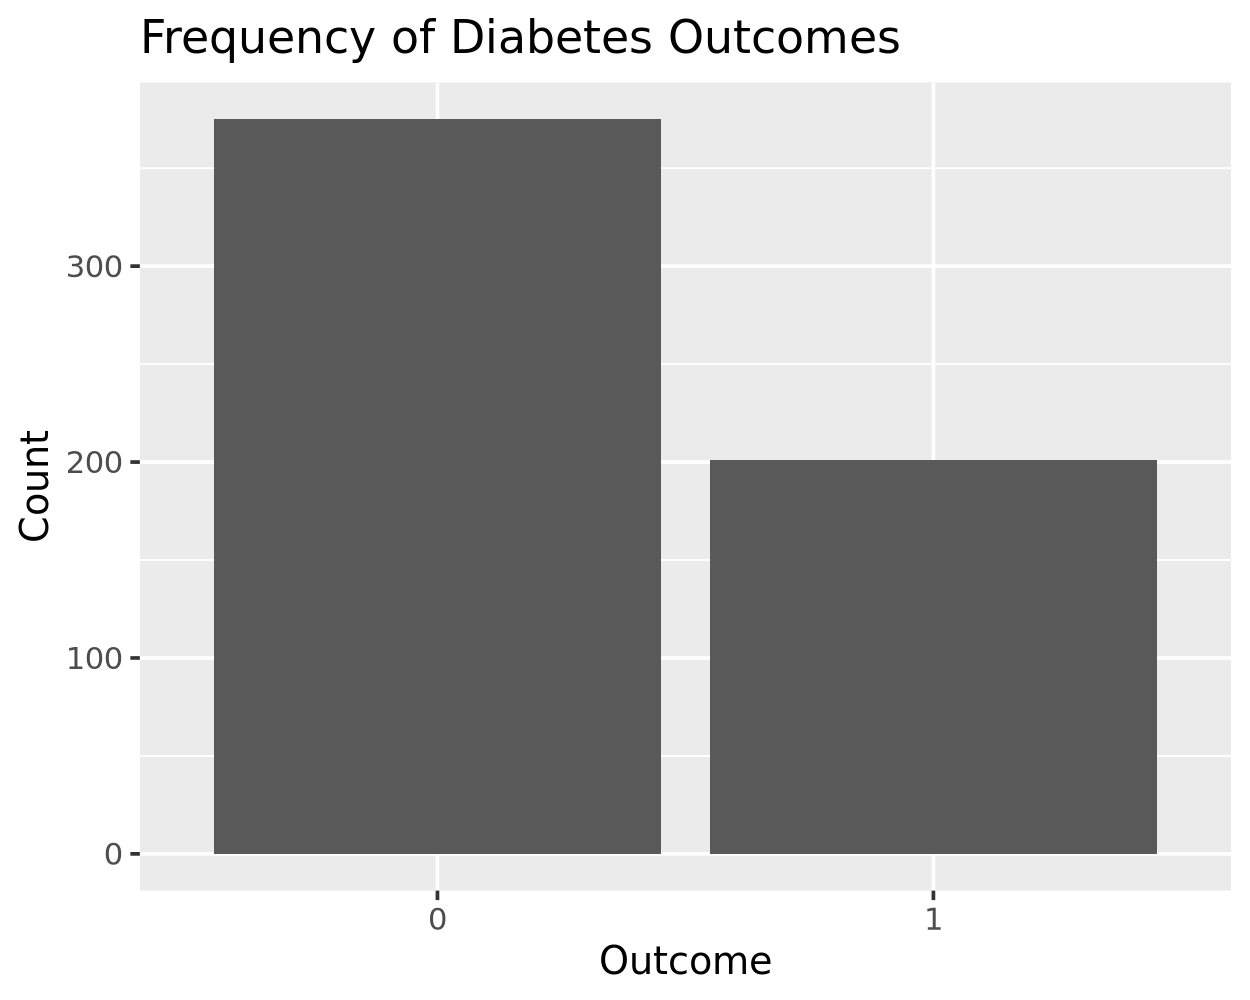

In [6]:
ggplot (diabetes_train, aes(x = Outcome)) +
   geom_bar() +
   labs (title = "Frequency of Diabetes Outcomes", 
         x = "Outcome",
         y = "Count"
         )

❓ Is the data balanced? I.e. do we have equal counts of each outcome?

**Answer:**

No, we have more nondiabetes than diabetes.


Run the code below to create a table for plotting the predictors we will use in our model: `Glucose` and `BMI`. 

In [7]:
plot_df = diabetes_train |>
    select(Outcome, Glucose, BMI) |>
    pivot_longer(cols = c(Glucose, BMI))

plot_df |> head() 

Outcome,name,value
<fct>,<chr>,<dbl>
0,Glucose,89.0
0,BMI,28.1
0,Glucose,115.0
0,BMI,35.3
0,Glucose,110.0
0,BMI,37.6


Using `plot_df`, make a chart showing the relationship of `Glucose` and `BMI` with `Outcome`. 

- use `geom_jitter` for your "geom"
- `facet_wrap` your chart by the `name` variable. (e.g. `facet_wrap(~name, ncol = 2, scales = 'free_x')`)

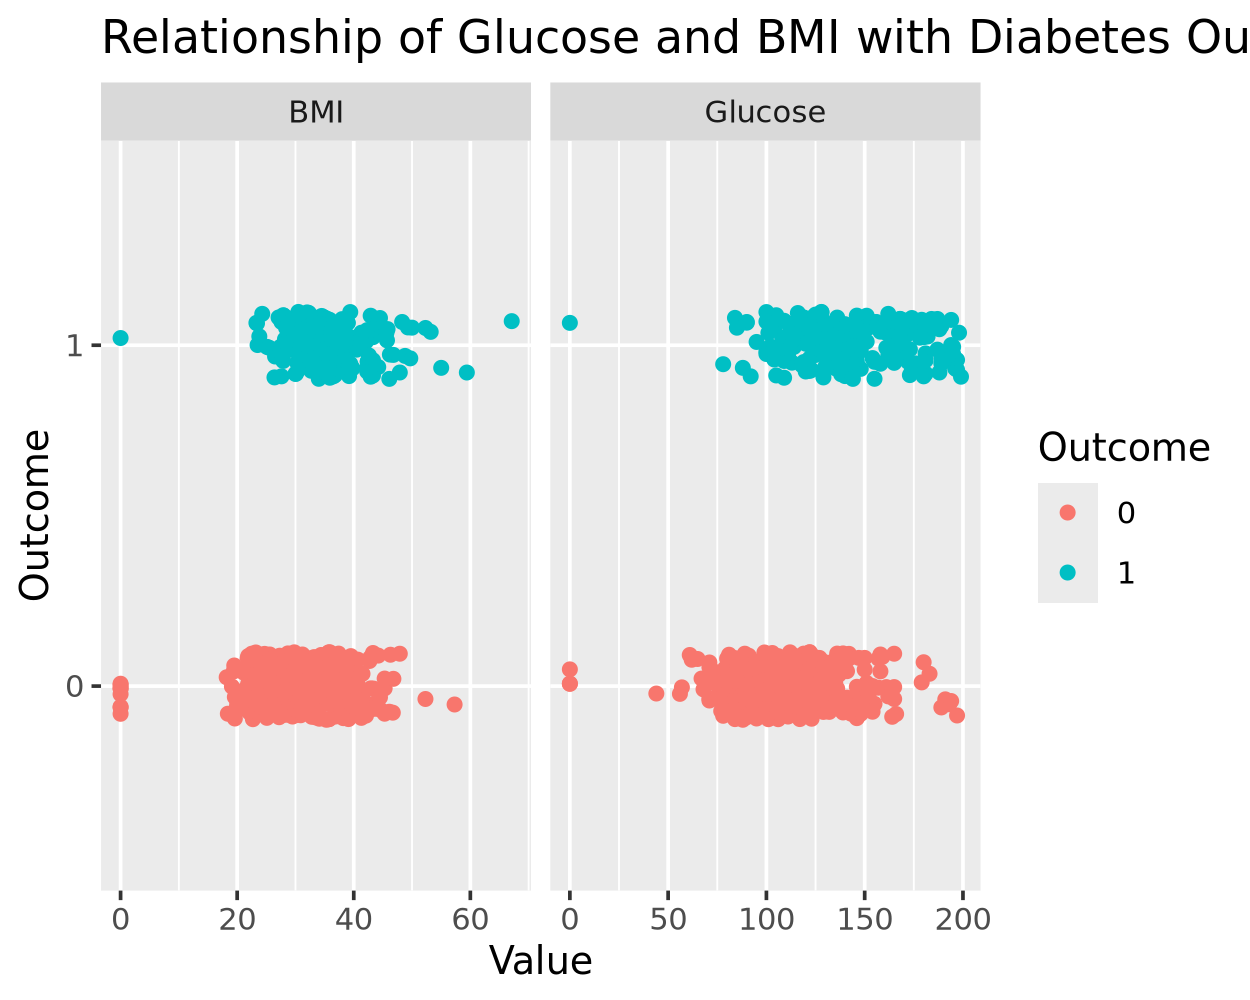

In [10]:
ggplot(plot_df, aes(x = value, y = Outcome, color = Outcome)) +
    geom_jitter(height = 0.1, width = 0) +
    facet_wrap (~name, ncol = 2, scales = "free_x") + 
    labs (x = "Value", 
          y = "Outcome", 
          title = "Relationship of Glucose and BMI with Diabetes Outcome") 



❓ What happens when you remove the `scales = 'free_x'` argument from the `facet_wrap` function?

**Answer:**

All facets will use the same x-axis scale.

Using your training data, build logistic regression model of `Outcome` with `BMI` and `Glucose` as predictors. 
- Use "glm" for you engine
- The formula for your fit function will be `Outcome ~ BMI + Glucose`

In [13]:
diabetes_mod <-logistic_reg()|>
  set_engine ("glm") |>
  fit (Outcome ~ BMI +Glucose, data = diabetes_train)

tidy(diabetes_mod)



term,estimate,std.error,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-7.48388887,0.699451124,-10.699660,1.021529e-26
BMI,0.07669117,0.015270052,5.022325,5.104963e-07
Glucose,0.03435579,0.003743489,9.177480,4.412961e-20


Using `augment` with your fitted model and the `diabetes_test` data as arguments, create a new dataset called `diabetes_test_wPred` that is the `diabetes_test` table including predictions from your model. 

In [15]:
diabetes_test_wPred<-augment(diabetes_mod, new_data = diabetes_test)

glimpse(diabetes_test_wPred)


Rows: 192
Columns: 12
$ .pred_class              <fct> 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, …
$ .pred_0                  <dbl> 0.9257840, 0.8227838, 0.9604340, 0.4507093, 0…
$ .pred_1                  <dbl> 0.074215994, 0.177216225, 0.039566017, 0.5492…
$ Pregnancies              <dbl> 1, 5, 8, 5, 1, 8, 9, 11, 10, 7, 1, 3, 3, 7, 1…
$ Glucose                  <dbl> 85, 116, 125, 166, 115, 99, 119, 143, 125, 14…
$ BloodPressure            <dbl> 66, 74, 96, 72, 70, 84, 80, 94, 70, 76, 66, 7…
$ SkinThickness            <dbl> 29, 0, 0, 19, 30, 0, 35, 33, 26, 0, 15, 36, 1…
$ Insulin                  <dbl> 0, 0, 0, 175, 96, 0, 0, 146, 115, 0, 140, 245…
$ BMI                      <dbl> 26.6, 25.6, 0.0, 25.8, 34.6, 35.4, 29.0, 36.6…
$ DiabetesPedigreeFunction <dbl> 0.351, 0.201, 0.232, 0.587, 0.529, 0.388, 0.2…
$ Age                      <dbl> 31, 30, 54, 51, 32, 50, 29, 51, 41, 43, 22, 2…
$ Outcome                  <fct> 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, …


Run the code below to generate a confusion matrix for your model predictions. 

(❗️Hint: See Table 4.4 from [*Introduction to Statistical Learning (Version 2)*](https://www.statlearning.com/) for an example confusion matrix.)

In [17]:


diabetes_test_wPred |> conf_mat(Outcome, .pred_class)

          Truth
Prediction   0   1
         0 117  34
         1   8  33

❓ Based on the confusion matrix above, 
- How many individuals had diabetes in your test data?
- Of those that actually had diabetes, how many were predicted to have diabetes by your model?
- How many individuals predicted to have diabetes did not have diabetes?

**Answer:**

67 individuals had diabetes in my test data

Of those that actually had diabetes, 33 were predicted to have diabetes by my model

8 individuals predicted to have diabetes did not have diabetes.